In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stat
from astropy.constants import eps0, c

In [7]:
data = np.fromfile('50M_6.2C_609MHz_5MSPS.dat',dtype='int16')-2**11

Let's get the mean and standard deviation of the data - **remember to subtract the mean from all the data to make it centred around 0!**

In [8]:
np.random.seed(0)
data = data - np.mean(data)

print(np.mean(data))

print(data.shape)

3.5458469938021154e-16
(50000000,)


We avoid the first 50000 sample because they are affected by the amplifiers starting up early on.

In [9]:
spl_size = 2091392

subspl = data[500000:spl_size+500000]

print(len(subspl))

2091392


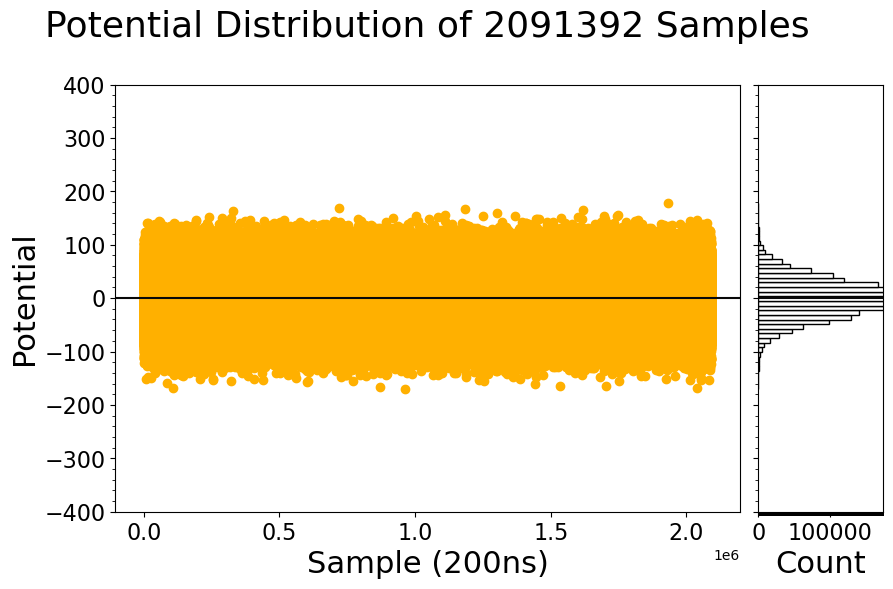

In [10]:

fig, axs = plt.subplots(1, 2, sharey=True, width_ratios=(10, 2))
plt.subplots_adjust(left=0, right=1.2, top=1, wspace=0.05)
lin_range = np.arange(0, spl_size, 1)

axs[0].axhline(0, color='#080808')
axs[1].axhline(0, color='#080808')

axs[0].set_yticks(np.arange(-400, 400, 20), minor=True)

axs[0].scatter(lin_range, subspl, color='#FFB000')
axs[0].set_ylim(-400, 400)

axs[1].hist(subspl, bins=40, edgecolor='black', color='white', orientation="horizontal")
axs[1].set_xlim(0, spl_size/12)
axs[1].set_xticks(np.arange(0, spl_size/12, 20), minor=True)

axs[0].set_title(f"Potential Distribution of {spl_size} Samples\n", fontsize=26)
axs[0].set_ylabel("Potential", fontsize=22)
axs[0].set_xlabel("Sample (200ns)", fontsize=22)

axs[1].set_xlabel("Count", fontsize=22)

axs[0].tick_params(labelsize=16)
axs[1].tick_params(labelsize=16)


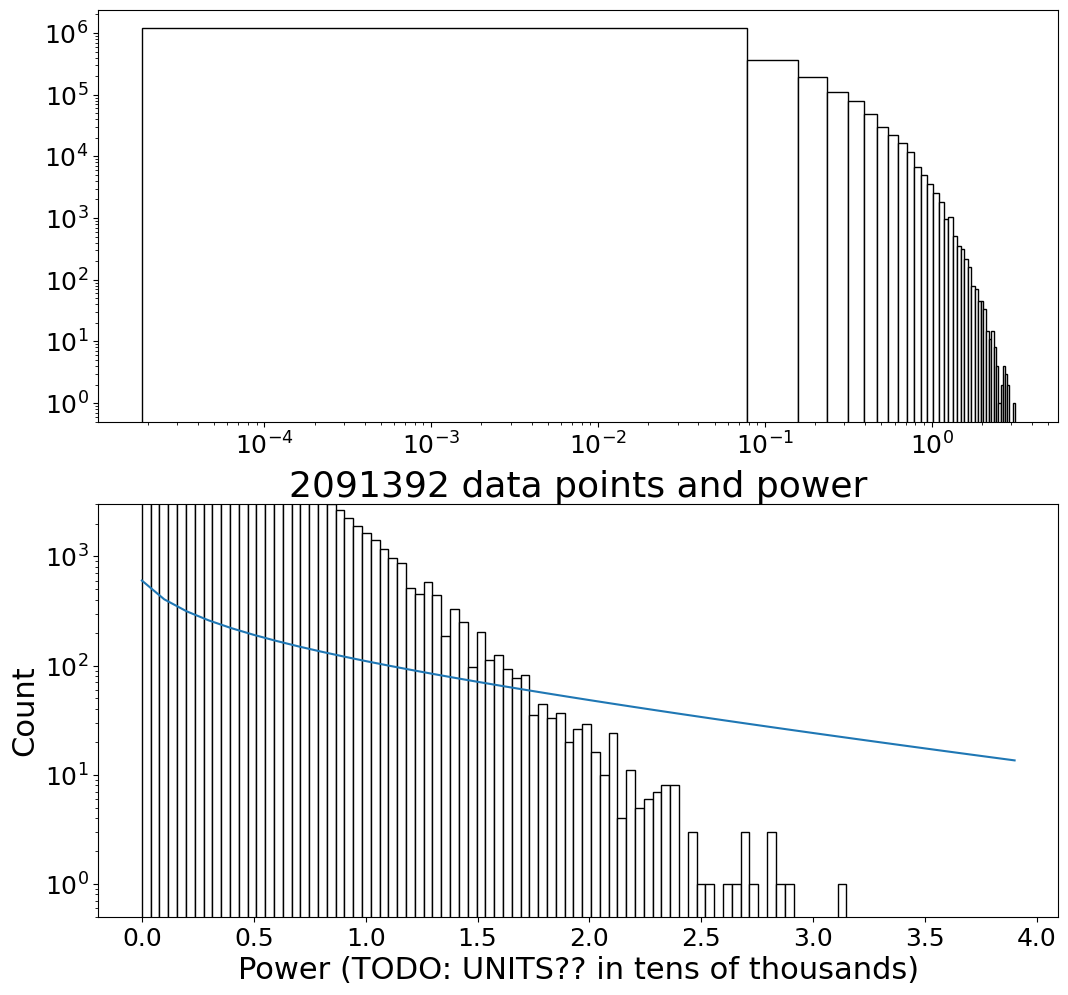

In [11]:
datasq = subspl ** 2 / 10000

datasq_range = np.arange(0, np.round(np.max(datasq)) + 1, 0.1)

fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(left=0, right=1.5, top=2)

axs[0].hist(datasq, bins=40, edgecolor='black', color='white')
axs[0].loglog()
axs[0].tick_params(labelsize=18)

axs[1].hist(datasq, bins=80, edgecolor='black', color='white')
axs[1].plot(datasq_range, stat.chi2.pdf(datasq_range + 0.1, 1)*10**2.7)
axs[1].semilogy()

axs[1].set_ylim(0.5, 3000)

axs[1].set_xlabel("Power (TODO: UNITS?? in tens of thousands)", fontsize=22)
axs[1].set_ylabel("Count", fontsize=22)
axs[1].set_title(f"{spl_size} data points and power", fontsize=26)
axs[1].tick_params(labelsize=18)

In [12]:
def adj_sum(data, ct):
    """
    Return NumPy array of ct-summed values from data. Length of array will be len(data) - (ct - 1).
    ct should be positive and non-zero.
    """
    adjs = []
    for i in range(len(data[ct-1:])):
        curr_sum = 0
        
        for j in range(i, i + ct):
            curr_sum += data[j]
        
        adjs.append(curr_sum)
    
    return np.array(adjs)

In [13]:
adj_cts = [1, 2, 4, 10, 100]

adj_sums = [adj_sum(datasq, i) for i in adj_cts]

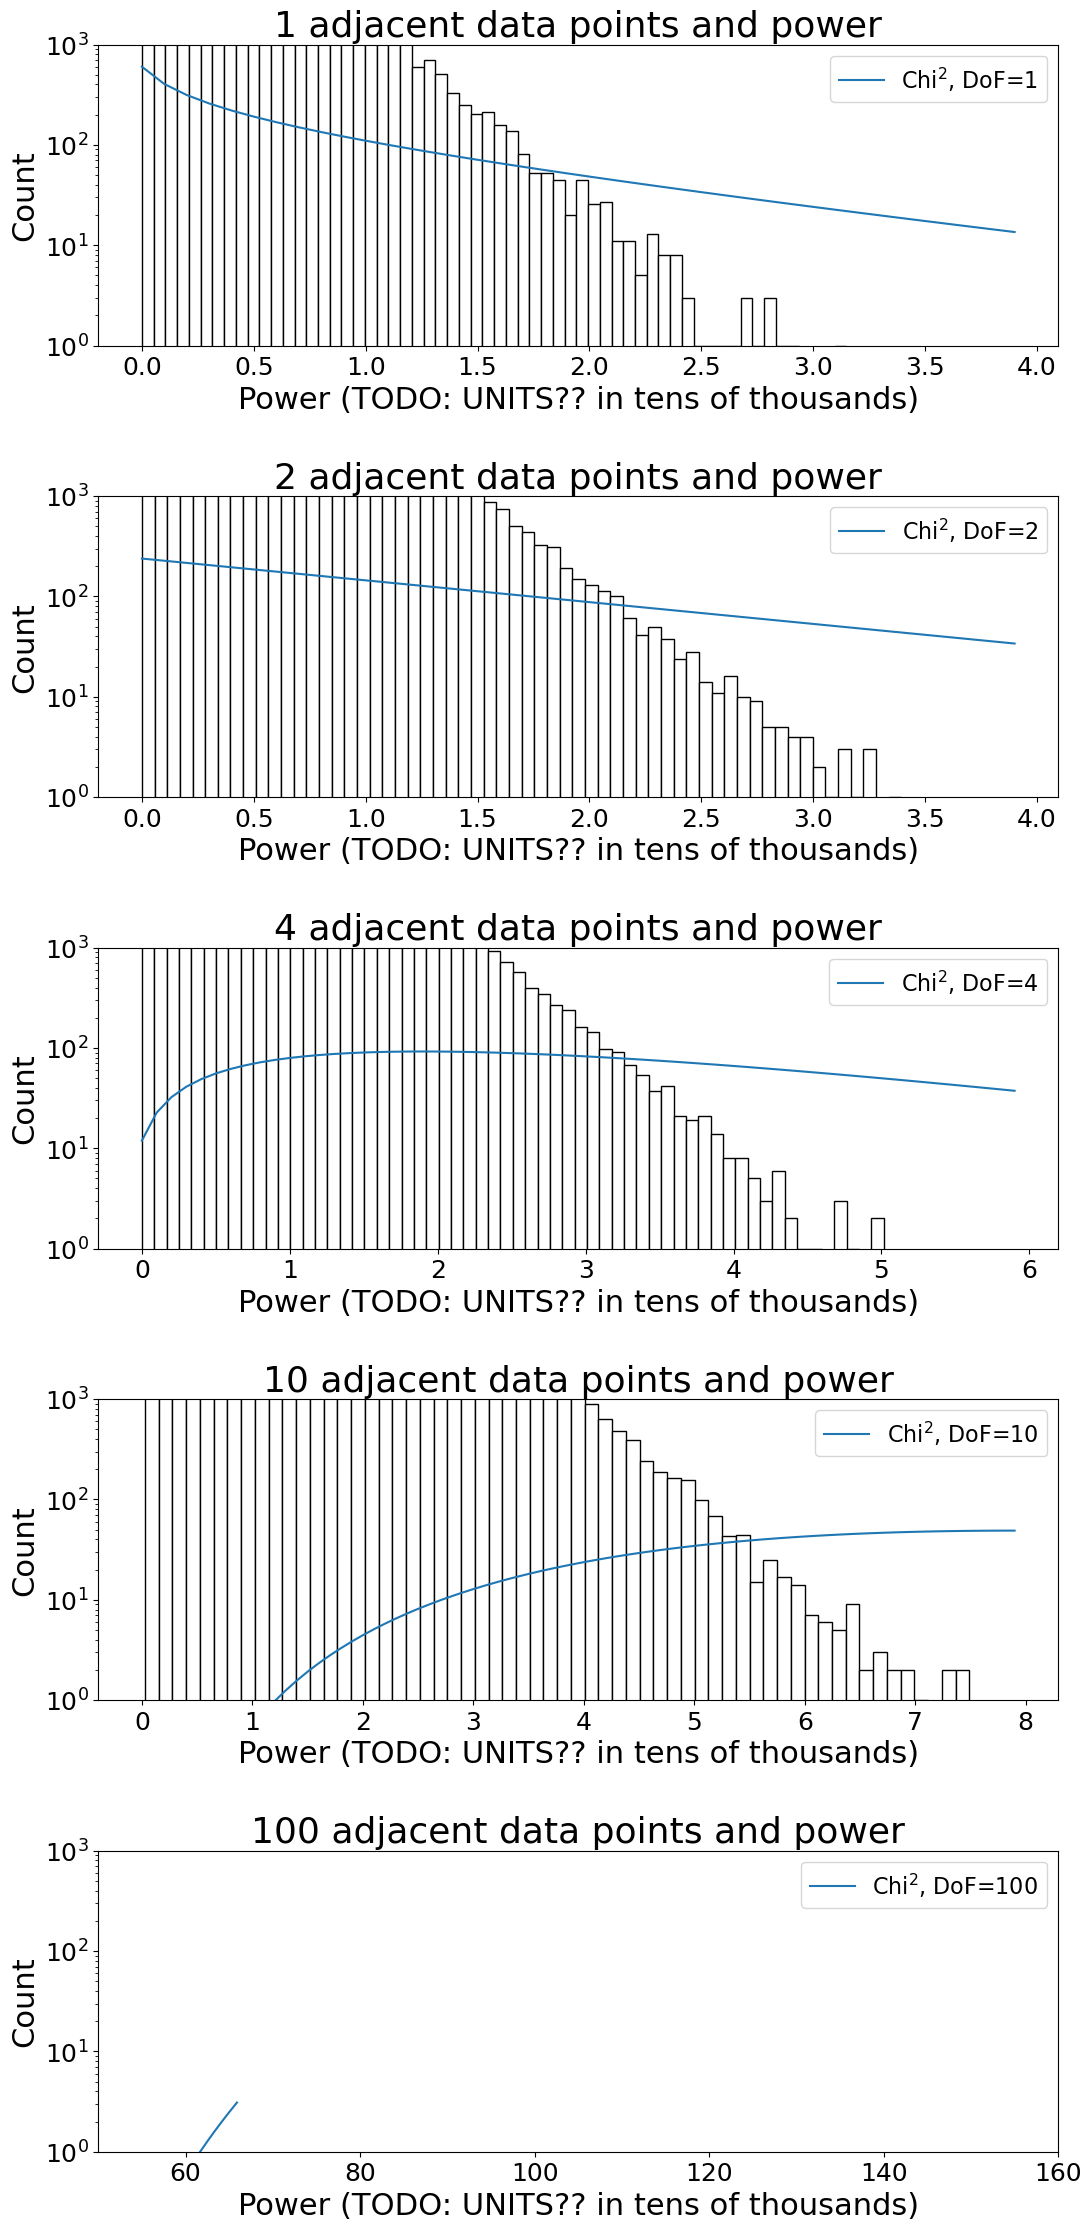

In [14]:
fig, axs = plt.subplots(5, 1)
plt.subplots_adjust(left=0, right=1.5, top=4.5, hspace=0.5)

i = 0

for ax in axs:
    ax.semilogy()
    ax.hist(adj_sums[i], bins=60, edgecolor='black', color='white')
    
    data_range = np.arange(0, np.round(np.max(adj_sums[i])) + 1, 0.1)
    
    ax.set_xlabel("Power (TODO: UNITS?? in tens of thousands)", fontsize=22)
    ax.set_ylabel("Count", fontsize=22)
    ax.set_title(f"{adj_cts[i]} adjacent data points and power", fontsize=26)
    ax.tick_params(labelsize=18)
    
    if i == len(adj_cts) - 1:
        data_range = np.arange(0, np.round(np.max(adj_sums[i])) + 40, 0.1)
        ax.plot(data_range, stat.chi2.pdf(data_range + 0.1, adj_cts[i])*10**3.5, label=f"Chi$^2$, DoF={adj_cts[i]}")
        ax.set_xlim(50, 160)
        
    else:
        ax.plot(data_range, stat.chi2.pdf(data_range + 0.1, adj_cts[i])*10**2.7, label=f"Chi$^2$, DoF={adj_cts[i]}")
    
    ax.legend(fontsize=16)
    ax.set_ylim(1, 1000)
    #ax.set_xticks(np.arange(0, 20, 2))
    #ax.set_xticks(np.arange(0, 20, 0.5), minor=True)
    i += 1

In [16]:
j = 4096
subspl_cuts = []

while j < 2091392:
    subspl_cuts.append(subspl[j-1024:j])
    j += 4096

ffts = [] 

for spl in subspl_cuts:
    ffts.append(np.fft.fft(spl))


powers = []

for fft in ffts:
    elems = []
    for elem in fft:
        elems.append(elem.real ** 2 + elem.imag ** 2)
    powers.append(elems)
    
powers = np.array(powers)

avg_power = np.mean(powers, axis=0)

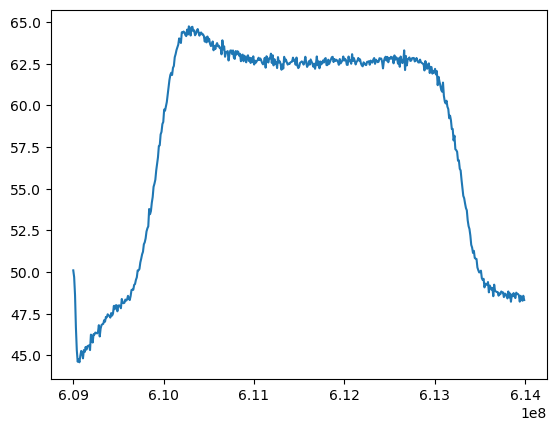

In [18]:
cadence = 1/5000000
LO = 609000000

fig, ax = plt.subplots(1, 1)
lin_range = np.arange(LO, 1/cadence + LO, 1 / (cadence * 512))

ax.plot(lin_range, 10*np.log10(avg_power[:512]))

# radiometer equation (T \propto P)
frac_uncert = (2/1)**0.5